# Mapa de GEH – Totales (Visum vs aforo)

Este notebook usa **solo las columnas de TOTALES**:
- `TOTAL_VOL` = volumen total asignado por **Visum**
- `TOTAL_COUNTS` = **aforo** total (IMEPLAN)

Para cada periodo (AP, LM, EA, PP) calcula el **GEH** en los links con aforo y los pinta sobre el mapa de Guadalajara:

| Color | GEH | Significado |
|---|---|---|
| 🟢 Verde | < 5 | Buen ajuste |
| 🟠 Naranja | 5 – 10 | Regular |
| 🔴 Rojo | > 10 | Mal ajuste |

Las calles sin aforo se dibujan en gris claro solo como referencia.

**Librerias:** `geopandas`, `matplotlib`, `contextily` (fondo del mapa) y `folium` (mapa interactivo).
Si falta alguna: `pip install contextily folium mapclassify`

In [5]:
pip install contextily folium mapclassify

Note: you may need to restart the kernel to use updated packages.


## 1. Configuracion

In [6]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RUTA = "/Users/ebonyvaladez/Desktop/Septimo/on campus/links asignacion"   # <-- ruta del archivo nuevo
CARPETA_SALIDA = "."                              # donde se guardan imagenes, html y excel

PERIODOS = ["AP", "LM", "EA", "PP"]
NOMBRE_PERIODO = {"AP": "AM Peak (4-9 h)", "LM": "Late Morning (9-12 h)",
                  "EA": "Early Afternoon (12-18 h)", "PP": "PM Peak (18-21 h)"}
HORAS = {"AP": 5, "LM": 3, "EA": 6, "PP": 3}
GEH_BASE = "GEH_hora"     # "GEH_hora" (volumen por hora, recomendado) o "GEH_periodo"

# Columnas de totales (los nombres vienen recortados por el .shp)
COLUMNAS = {
    "AP": {"aforo": "TOTAL_CO~9", "visum": "TOTAL_V~10"},
    "LM": {"aforo": "TOTAL_C~11", "visum": "TOTAL_V~12"},
    "EA": {"aforo": "TOTAL_C~13", "visum": "TOTAL_V~14"},
    "PP": {"aforo": "TOTAL_C~15", "visum": "TOTAL_V~16"},
}

COLORES = {"< 5": "#2e9e44", "5 - 10": "#f28e2b", "> 10": "#d62728"}

## 2. Cargar datos y revisar columnas

In [7]:
gdf = gpd.read_file(RUTA)
print("Links:", f"{len(gdf):,}")
print("Sistema de coordenadas:", gdf.crs)
print("Columnas:", gdf.columns.tolist())

# --- Detectar automaticamente las columnas TOTAL ---
def detectar_totales(columnas):
    tot = [c for c in columnas if "TOTAL" in c.upper()]
    det = {p: {} for p in PERIODOS}
    # Caso 1: nombres completos con periodo (ej. TOTAL_COUNTS_AP, TOTAL_VOL_AP)
    for c in tot:
        cu = c.upper()
        for p in PERIODOS:
            if cu.endswith("_" + p):
                det[p]["aforo" if "COUNT" in cu else "visum"] = c
    if all(len(det[p]) == 2 for p in PERIODOS):
        return det
    # Caso 2: nombres recortados (ej. TOTAL_CO~9, TOTAL_V~10): se asignan por orden AP, LM, EA, PP
    resto = [c.upper().split("TOTAL", 1)[1].lstrip("_ ") for c in tot]
    aforos = [c for c, r in zip(tot, resto) if r.startswith("C")]
    visums = [c for c, r in zip(tot, resto) if r.startswith("V")]
    if len(aforos) == len(visums) == len(PERIODOS):
        return {p: {"aforo": a, "visum": v} for p, a, v in zip(PERIODOS, aforos, visums)}
    return None

COLUMNAS_DET = detectar_totales(gdf.columns)
if COLUMNAS_DET is None:
    print("\nNo se pudieron detectar las columnas TOTAL. Columnas con TOTAL:",
          [c for c in gdf.columns if "TOTAL" in c.upper()])
    print("Llena el diccionario COLUMNAS de la celda 1 a mano con esos nombres.")
else:
    COLUMNAS = COLUMNAS_DET
    print("\nColumnas usadas:")
    for p in PERIODOS:
        print(f"  {p}: aforo = {COLUMNAS[p]['aforo']!r} | Visum = {COLUMNAS[p]['visum']!r}")


Links: 228,360
Sistema de coordenadas: EPSG:4326
Columnas: ['NO', 'FROMNODENO', 'TONODENO', 'CAR_COUN~1', 'VOL_C_AP', 'FREIGHT_~2', 'VOL_HF_AP', 'VOL_LF_AP', 'CAR_COUN~3', 'VOL_C_LM', 'FREIGHT_~4', 'VOL_HF_LM', 'VOL_LF_LM', 'CAR_COUN~5', 'VOL_C_EA', 'FREIGHT_~6', 'VOL_HF_EA', 'VOL_LF_EA', 'CAR_COUN~7', 'VOL_C_PP', 'FREIGHT_~8', 'VOL_HF_PP', 'VOL_LF_PP', 'TOTAL_CO~9', 'TOTAL_V~10', 'TOTAL_C~11', 'TOTAL_V~12', 'TOTAL_C~13', 'TOTAL_V~14', 'TOTAL_C~15', 'TOTAL_V~16', 'geometry']

Columnas usadas:
  AP: aforo = 'TOTAL_CO~9' | Visum = 'TOTAL_V~10'
  LM: aforo = 'TOTAL_C~11' | Visum = 'TOTAL_V~12'
  EA: aforo = 'TOTAL_C~13' | Visum = 'TOTAL_V~14'
  PP: aforo = 'TOTAL_C~15' | Visum = 'TOTAL_V~16'


## 3. Calcular GEH por link y periodo
$GEH = \\sqrt{\\dfrac{2(M-C)^2}{M+C}}$, con **M = Visum** y **C = aforo**. Solo links con aforo > 0.

In [8]:
def geh(m, c):
    return np.sqrt(2 * (m - c) ** 2 / (m + c))

for p in PERIODOS:
    c = pd.to_numeric(gdf[COLUMNAS[p]["aforo"]], errors="coerce").fillna(0)
    m = pd.to_numeric(gdf[COLUMNAS[p]["visum"]], errors="coerce").fillna(0)
    gdf[f"aforo_{p}"] = c
    gdf[f"visum_{p}"] = m
    gdf[f"dif_{p}"] = m - c
    gdf[f"pct_error_{p}"] = np.where(c > 0, (m - c) / c * 100, np.nan)
    gdf[f"GEH_periodo_{p}"] = np.where(c > 0, geh(m, c), np.nan)
    gdf[f"GEH_hora_{p}"] = np.where(c > 0, geh(m / HORAS[p], c / HORAS[p]), np.nan)
    gdf[f"GEH_{p}"] = gdf[f"{GEH_BASE}_{p}"]
    gdf[f"rango_{p}"] = pd.cut(gdf[f"GEH_{p}"], [-np.inf, 5, 10, np.inf], right=False,
                               labels=["< 5", "5 - 10", "> 10"])

# Proyeccion para el mapa (Web Mercator, la que usan los mapas de fondo)
if gdf.crs is None:
    print("El archivo no trae sistema de coordenadas; se asume EPSG:4326. Revisar el .prj.")
    gdf = gdf.set_crs(4326)
gdf_m = gdf.to_crs(3857)

## 4. Resumen por periodo

In [9]:
filas = []
for p in PERIODOS:
    sub = gdf[gdf[f"aforo_{p}"] > 0]
    g = sub[f"GEH_{p}"]
    filas.append({
        "periodo": p,
        "links_con_aforo": len(sub),
        "aforo_total": round(sub[f"aforo_{p}"].sum()),
        "visum_total": round(sub[f"visum_{p}"].sum()),
        "dif_total_%": round((sub[f"visum_{p}"].sum() - sub[f"aforo_{p}"].sum()) / sub[f"aforo_{p}"].sum() * 100, 1),
        "GEH_mediana": round(g.median(), 2),
        "%_GEH<5": round((g < 5).mean() * 100, 1),
        "%_GEH_5a10": round(((g >= 5) & (g < 10)).mean() * 100, 1),
        "%_GEH>10": round((g >= 10).mean() * 100, 1),
    })
resumen = pd.DataFrame(filas).set_index("periodo")
resumen

,links_con_aforo,aforo_total,visum_total,dif_total_%,GEH_mediana,%_GEH<5,%_GEH_5a10,%_GEH>10
periodo,,,,,,,,
AP,541,779097,622795,-20.1,7.87,35.7,27.2,37.2
LM,540,682721,294251,-56.9,13.50,17.4,17.2,65.4
EA,542,815051,534447,-34.4,8.11,32.8,25.6,41.5
PP,541,899198,534291,-40.6,12.81,20.3,20.7,59.0


## 5. Mapas estaticos (uno por periodo)
- Gris claro: red completa (sin aforo).
- Color: links con aforo, segun su GEH.
- Los rojos se dibujan al final para que no queden tapados.

Si `contextily` esta instalado y hay internet, se agrega el mapa de calles de fondo.

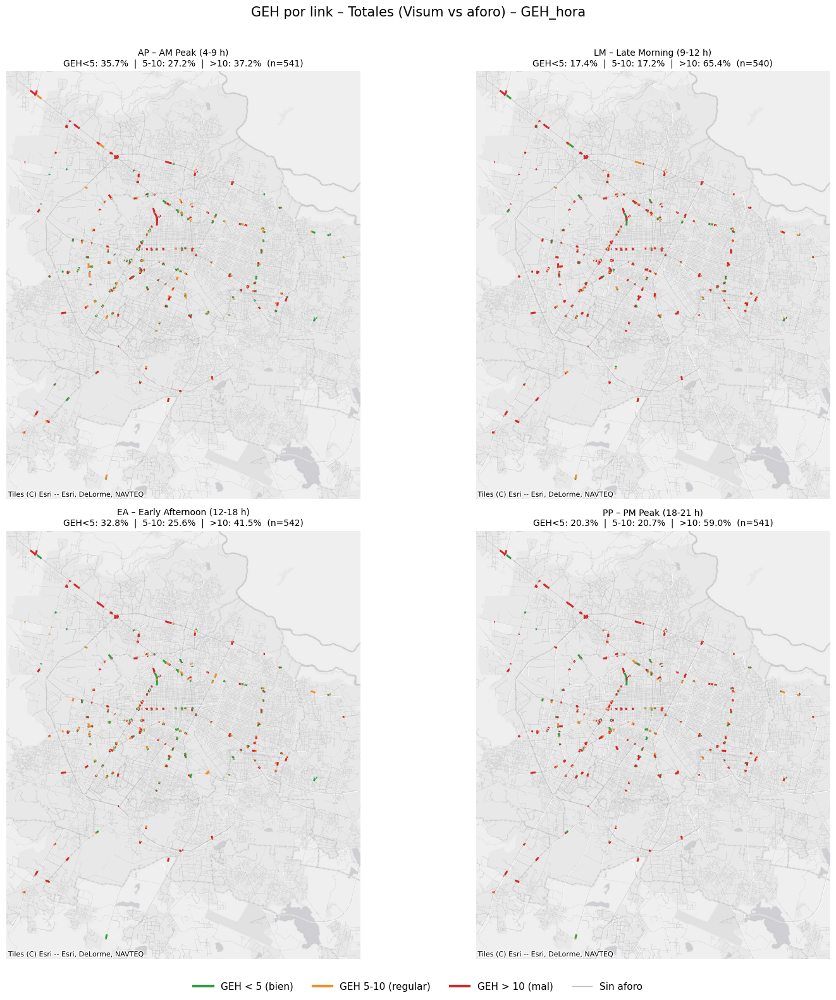

In [10]:
try:
    import contextily as cx
    HAY_FONDO = True
except ImportError:
    HAY_FONDO = False
    print("contextily no esta instalado: los mapas saldran sin fondo (pip install contextily)")

# Recuadro del mapa: alrededor de los links con aforo (con margen)
con_aforo_alguno = gdf_m[[f"aforo_{p}" for p in PERIODOS]].gt(0).any(axis=1)
xmin, ymin, xmax, ymax = gdf_m[con_aforo_alguno].total_bounds
mx, my = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
LIMITES = (xmin - mx, xmax + mx, ymin - my, ymax + my)

def dibujar_periodo(ax, p):
    gdf_m.plot(ax=ax, color="#bbbbbb", linewidth=0.15, alpha=0.5, zorder=1)
    sub = gdf_m[gdf_m[f"aforo_{p}"] > 0]
    for z, rango in enumerate(["< 5", "5 - 10", "> 10"]):
        parte = sub[sub[f"rango_{p}"] == rango]
        if len(parte):
            parte.plot(ax=ax, color=COLORES[rango], linewidth=2.2, zorder=3 + z)
    ax.set_xlim(LIMITES[0], LIMITES[1]); ax.set_ylim(LIMITES[2], LIMITES[3])
    if HAY_FONDO:
        try:
            cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, zorder=0)
        except Exception as e:
            print("No se pudo cargar el fondo:", e)
    r = resumen.loc[p]
    ax.set_title(f"{p} – {NOMBRE_PERIODO[p]}\n"
                 f"GEH<5: {r['%_GEH<5']}%  |  5-10: {r['%_GEH_5a10']}%  |  >10: {r['%_GEH>10']}%  (n={int(r['links_con_aforo'])})",
                 fontsize=10)
    ax.set_axis_off()

leyenda = [Line2D([0], [0], color=COLORES["< 5"], lw=3, label="GEH < 5 (bien)"),
           Line2D([0], [0], color=COLORES["5 - 10"], lw=3, label="GEH 5-10 (regular)"),
           Line2D([0], [0], color=COLORES["> 10"], lw=3, label="GEH > 10 (mal)"),
           Line2D([0], [0], color="#bbbbbb", lw=1, label="Sin aforo")]

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    dibujar_periodo(ax, p)
fig.legend(handles=leyenda, loc="lower center", ncol=4, fontsize=11, frameon=False)
fig.suptitle(f"GEH por link – Totales (Visum vs aforo) – {GEH_BASE}", fontsize=15)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.savefig(f"{CARPETA_SALIDA}/mapa_GEH_totales_4periodos.png", dpi=200, bbox_inches="tight")
plt.show()

Un periodo en grande (cambiar `PERIODO_GRANDE`):

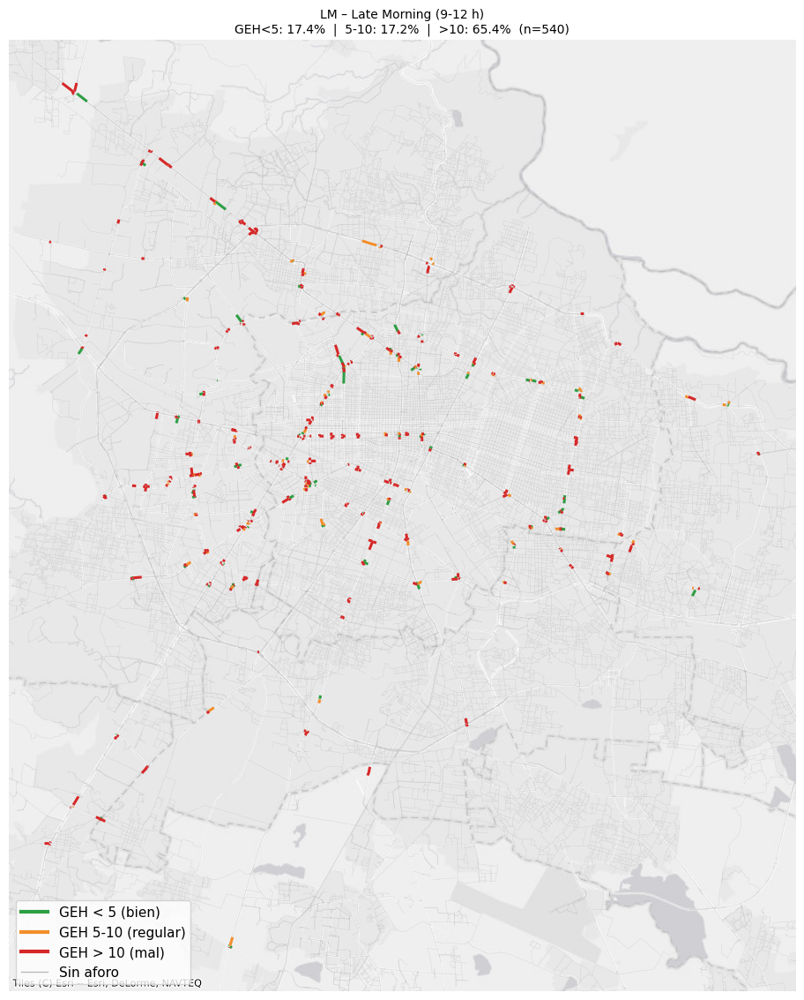

In [11]:
PERIODO_GRANDE = "LM"
fig, ax = plt.subplots(figsize=(14, 14))
dibujar_periodo(ax, PERIODO_GRANDE)
ax.legend(handles=leyenda, loc="lower left", fontsize=11)
plt.savefig(f"{CARPETA_SALIDA}/mapa_GEH_totales_{PERIODO_GRANDE}.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Mapa de sesgo: ¿Visum pone de mas o de menos?
El GEH dice *que tan mal*, pero no *hacia donde*. Este mapa colorea por direccion del error:
- **Rojo:** Visum pone **de mas** (sobreestima)
- **Azul:** Visum pone **de menos** (subestima)
- Entre mas intenso, mayor el % de error (limitado a ±100 %).

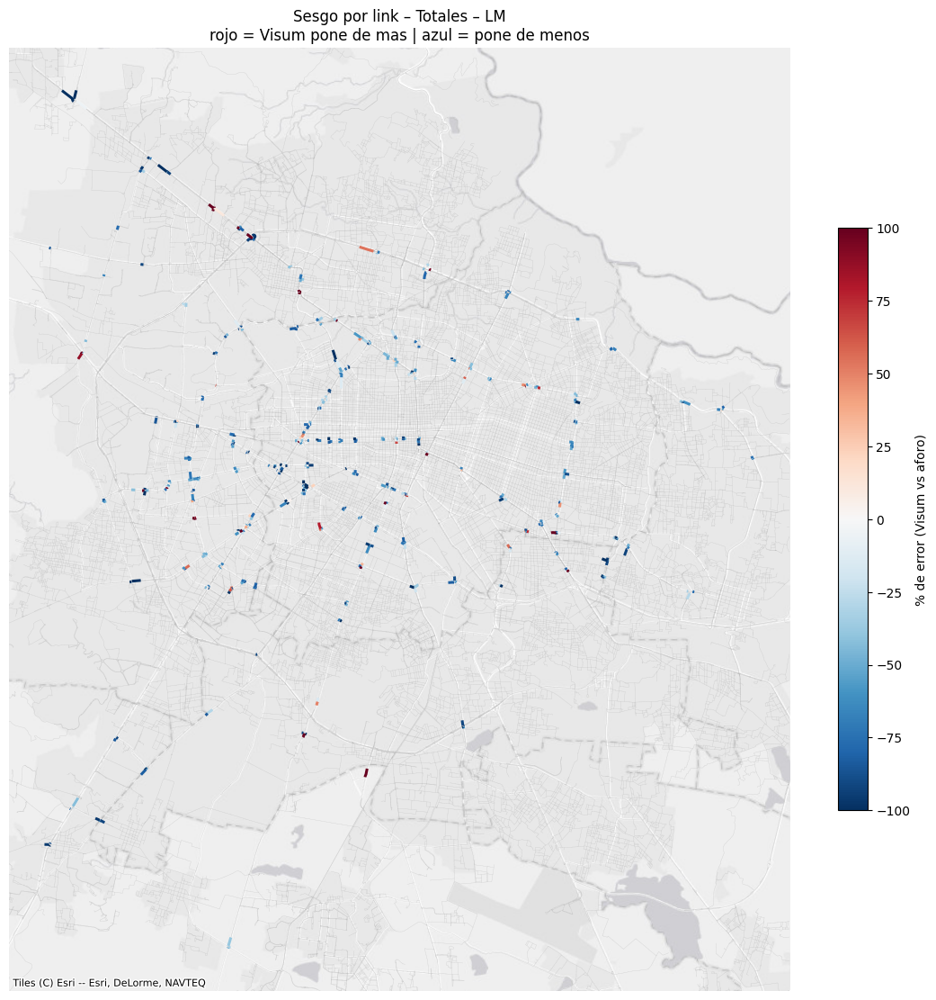

In [12]:
PERIODO_SESGO = "LM"
sub = gdf_m[gdf_m[f"aforo_{PERIODO_SESGO}"] > 0].copy()
sub["pct_lim"] = sub[f"pct_error_{PERIODO_SESGO}"].clip(-100, 100)

fig, ax = plt.subplots(figsize=(14, 14))
gdf_m.plot(ax=ax, color="#bbbbbb", linewidth=0.15, alpha=0.5, zorder=1)
sub.sort_values("pct_lim", key=abs).plot(ax=ax, column="pct_lim", cmap="RdBu_r", vmin=-100, vmax=100,
                                         linewidth=2.2, legend=True, zorder=3,
                                         legend_kwds={"label": "% de error (Visum vs aforo)", "shrink": 0.6})
ax.set_xlim(LIMITES[0], LIMITES[1]); ax.set_ylim(LIMITES[2], LIMITES[3])
if HAY_FONDO:
    try: cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, zorder=0)
    except Exception as e: print("No se pudo cargar el fondo:", e)
ax.set_title(f"Sesgo por link – Totales – {PERIODO_SESGO}\nrojo = Visum pone de mas | azul = pone de menos")
ax.set_axis_off()
plt.savefig(f"{CARPETA_SALIDA}/mapa_sesgo_totales_{PERIODO_SESGO}.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Links que fallan en todos los periodos
Links con aforo en los 4 periodos y **GEH > 10 en los 4**. Si una calle falla siempre, probablemente es un problema de la **red** o del **aforo**, no de un horario en particular.

In [13]:
con_aforo_4 = gdf[[f"aforo_{p}" for p in PERIODOS]].gt(0).all(axis=1)
falla_4 = con_aforo_4 & gdf[[f"GEH_{p}" for p in PERIODOS]].ge(10).all(axis=1)
falla_alguno = gdf[[f"GEH_{p}" for p in PERIODOS]].ge(10).sum(axis=1)

print(f"Links con aforo en los 4 periodos: {con_aforo_4.sum()}")
print(f"Links con GEH > 10 en los 4 periodos: {falla_4.sum()}")

cols = (["NO", "FROMNODENO", "TONODENO"] +
        [f"{x}_{p}" for p in PERIODOS for x in ("aforo", "visum", "GEH")])
links_falla_siempre = gdf.loc[falla_4, cols].round(1).sort_values("GEH_LM", ascending=False)
links_falla_siempre.head(20)

Links con aforo en los 4 periodos: 540
Links con GEH > 10 en los 4 periodos: 129


,NO,FROMNODENO,TONODENO,aforo_AP,visum_AP,GEH_AP,aforo_LM,visum_LM,GEH_LM,aforo_EA,visum_EA,GEH_EA,aforo_PP,visum_PP,GEH_PP
220513,478205,199581,199575,21316.1,1390,83.6,11893.3,448,84.1,10836.7,661,54.8,9925,281,77.9
121851,248556,98874,80414,9191.1,417,56.6,5330.0,108,57.8,6011.4,122,43.4,7048,375,63.2
121847,248554,98873,80179,9868.0,877,54.9,5490.5,384,54.4,6064.3,677,37.9,6968,945,55.3
216609,457816,189999,153949,5394.7,1703,27.7,3435.0,0,47.9,3758.6,0,35.4,3658,0,49.4
185040,373053,153184,199553,6117.1,1359,34.8,3780.0,137,47.5,4037.1,199,34.0,3992,210,47.6
142470,321167,131687,131688,3592.0,248,34.1,3490.2,114,45.9,4949.9,0,40.6,5759,168,59.3
158713,333801,137514,137366,7362.7,781,46.1,3675.4,222,45.2,4159.6,881,26.7,4824,797,43.9
54150,112127,44910,131414,3143.8,318,30.4,3317.7,93,45.1,4502.0,715,30.3,4756,790,43.5
210519,439462,181392,181389,2440.2,0,31.2,2723.6,0,42.6,3047.1,66,30.8,3288,154,43.6
186447,375599,154137,135910,4163.7,1150,26.1,3163.3,183,42.1,3711.5,401,29.8,3551,87,46.9


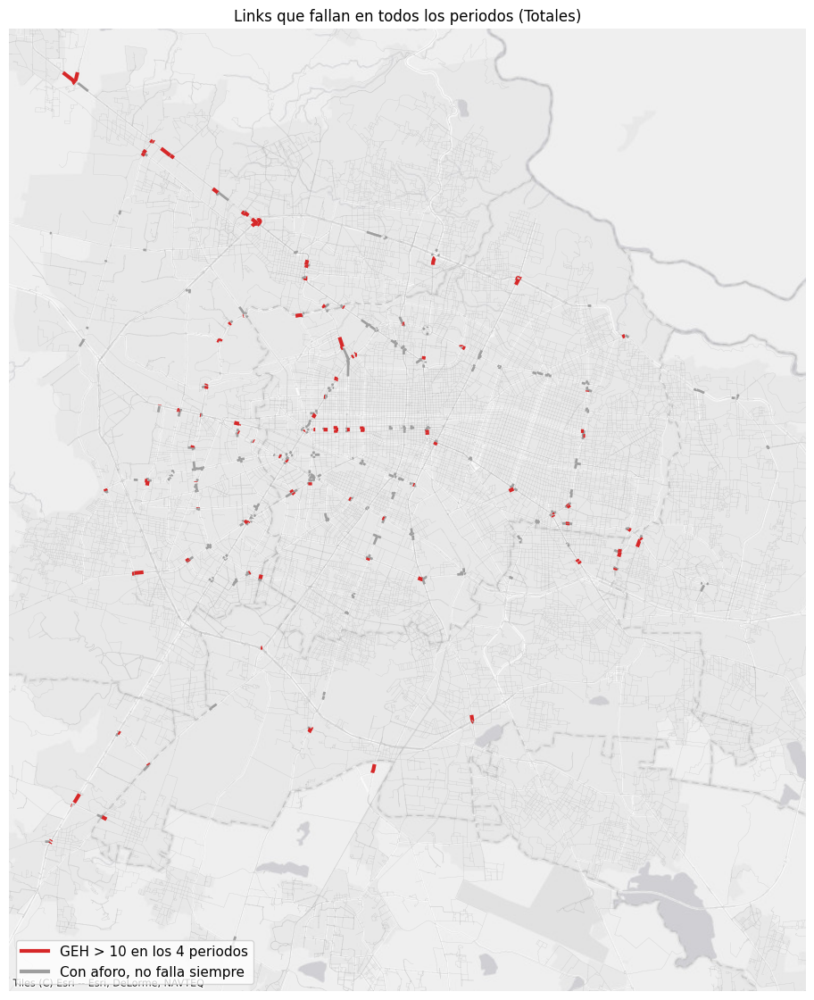

In [14]:
fig, ax = plt.subplots(figsize=(14, 14))
gdf_m.plot(ax=ax, color="#bbbbbb", linewidth=0.15, alpha=0.5, zorder=1)
base = gdf_m[con_aforo_4]
base[~falla_4[con_aforo_4]].plot(ax=ax, color="#9e9e9e", linewidth=2, zorder=2)
gdf_m[falla_4].plot(ax=ax, color=COLORES["> 10"], linewidth=3, zorder=3)
ax.set_xlim(LIMITES[0], LIMITES[1]); ax.set_ylim(LIMITES[2], LIMITES[3])
if HAY_FONDO:
    try: cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, zorder=0)
    except Exception as e: print("No se pudo cargar el fondo:", e)
ax.legend(handles=[Line2D([0], [0], color=COLORES["> 10"], lw=3, label="GEH > 10 en los 4 periodos"),
                   Line2D([0], [0], color="#9e9e9e", lw=3, label="Con aforo, no falla siempre")],
          loc="lower left", fontsize=11)
ax.set_title("Links que fallan en todos los periodos (Totales)")
ax.set_axis_off()
plt.savefig(f"{CARPETA_SALIDA}/mapa_links_fallan_siempre.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Mapa interactivo: clic en un link para ver su informacion
- **Pasa el mouse** sobre una calle: muestra su GEH del periodo.
- **Da clic**: se abre una ventana con aforo, Visum, diferencia, % de error y GEH en **los 4 periodos**.
- **Arriba a la derecha** puedes elegir el periodo y el mapa de fondo (gris, calles o satelite).

Se guarda como `.html`: se abre en cualquier navegador y se puede compartir.


In [15]:
import folium

# Links con aforo total en al menos un periodo
con_aforo = gdf[[f"aforo_{p}" for p in PERIODOS]].gt(0).any(axis=1)
capa = gdf.loc[con_aforo].copy()

# Texto de la ventana (popup) para cada link: tabla con los 4 periodos
def fmt(x, dec=0):
    return "-" if pd.isna(x) else f"{x:,.{dec}f}"

def popup_html(fila):
    filas = ""
    for p in PERIODOS:
        if fila[f"aforo_{p}"] > 0:
            rango = str(fila[f"rango_{p}"])
            color = COLORES.get(rango, "#999")
            filas += (f"<tr><td><b>{p}</b></td><td>{fmt(fila[f'aforo_{p}'])}</td>"
                      f"<td>{fmt(fila[f'visum_{p}'])}</td><td>{fmt(fila[f'dif_{p}'])}</td>"
                      f"<td>{fmt(fila[f'pct_error_{p}'], 1)}%</td>"
                      f"<td style='background:{color};color:white;text-align:center'><b>{fmt(fila[f'GEH_{p}'], 1)}</b></td></tr>")
        else:
            filas += f"<tr><td><b>{p}</b></td><td colspan='5' style='color:#999'>sin aforo</td></tr>"
    return (f"<div style='font-family:sans-serif;font-size:12px'>"
            f"<b>Link {int(fila['NO'])}</b> &nbsp;(nodo {int(fila['FROMNODENO'])} &rarr; {int(fila['TONODENO'])})"
            f"<table border='1' style='border-collapse:collapse;margin-top:6px' cellpadding='4'>"
            f"<tr style='background:#eee'><th>Periodo</th><th>Aforo</th><th>Visum</th><th>Dif.</th><th>% error</th><th>GEH</th></tr>"
            f"{filas}</table></div>")

capa["popup"] = capa.apply(popup_html, axis=1)
capa = capa.to_crs(4326)

# Mapa base, centrado en los links con aforo
centro = capa.geometry.union_all().centroid if hasattr(capa.geometry, "union_all") else capa.geometry.unary_union.centroid
mapa = folium.Map(location=[centro.y, centro.x], zoom_start=12, tiles=None)
folium.TileLayer("OpenStreetMap", name="Calles (OpenStreetMap)").add_to(mapa)
folium.TileLayer("Esri.WorldGrayCanvas", name="Gris (Esri)").add_to(mapa)
folium.TileLayer("Esri.WorldImagery", name="Satelite (Esri)").add_to(mapa)

# Una capa por periodo (se elige arriba a la derecha)
for p in PERIODOS:
    sub = capa[capa[f"aforo_{p}"] > 0]
    grupo = folium.FeatureGroup(name=f"GEH {p} - {NOMBRE_PERIODO[p]}", overlay=False, show=(p == "AP"))
    for _, fila in sub.iterrows():
        rango = str(fila[f"rango_{p}"])
        folium.GeoJson(
            fila.geometry.__geo_interface__,
            style_function=lambda _, c=COLORES.get(rango, "#999"): {"color": c, "weight": 7, "opacity": 0.9},
            highlight_function=lambda _: {"weight": 11, "color": "#000000"},
            tooltip=f"Link {int(fila['NO'])} | {p}: GEH {fmt(fila[f'GEH_{p}'], 1)} "
                    f"(aforo {fmt(fila[f'aforo_{p}'])}, Visum {fmt(fila[f'visum_{p}'])})",
            popup=folium.Popup(fila["popup"], max_width=450),
        ).add_to(grupo)
    grupo.add_to(mapa)

folium.LayerControl(collapsed=False).add_to(mapa)

# Leyenda
leyenda_html = f"""
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
            padding: 10px 14px; border: 1px solid #ccc; border-radius: 6px; font-family: sans-serif; font-size: 13px;">
<b>GEH ({GEH_BASE})</b><br>
<span style="color:{COLORES['< 5']}">&#9644;&#9644;</span> &lt; 5 (bien)<br>
<span style="color:{COLORES['5 - 10']}">&#9644;&#9644;</span> 5 - 10 (regular)<br>
<span style="color:{COLORES['> 10']}">&#9644;&#9644;</span> &gt; 10 (mal)<br>
<i>Clic en un link para ver el detalle</i>
</div>"""
mapa.get_root().html.add_child(folium.Element(leyenda_html))

mapa.save(f"{CARPETA_SALIDA}/mapa_interactivo_GEH_totales.html")
print("Guardado: mapa_interactivo_GEH_totales.html (abrelo en el navegador)")
display(mapa)


Guardado: mapa_interactivo_GEH_totales.html (abrelo en el navegador)


In [17]:
p = "AP"
sub = capa[capa[f"aforo_{p}"] > 0]
print("Links dibujados en", p, ":", len(sub))

# Cuantos 'lugares' distintos hay (links a menos de ~100 m se cuentan como uno)
pts = sub.to_crs(3857).geometry.centroid
lugares = set(zip((pts.x // 100).astype(int), (pts.y // 100).astype(int)))
print("Lugares distintos aprox.:", len(lugares))

Links dibujados en AP : 541
Lugares distintos aprox.: 450


## 9. Exportar

In [16]:
cols_export = (["NO", "FROMNODENO", "TONODENO"] +
               [f"{x}_{p}" for p in PERIODOS
                for x in ("aforo", "visum", "dif", "pct_error", "GEH_periodo", "GEH_hora")])
con_algun_aforo = gdf[[f"aforo_{p}" for p in PERIODOS]].gt(0).any(axis=1)

with pd.ExcelWriter(f"{CARPETA_SALIDA}/GEH_totales_por_link.xlsx") as xw:
    resumen.to_excel(xw, sheet_name="resumen")
    gdf.loc[con_algun_aforo, cols_export].round(2).to_excel(xw, sheet_name="por_link", index=False)
    links_falla_siempre.to_excel(xw, sheet_name="fallan_siempre", index=False)

# Capa geografica para abrir en QGIS o Visum
capa = gdf.loc[con_algun_aforo, cols_export + ["geometry"]].copy()
capa.to_file(f"{CARPETA_SALIDA}/GEH_totales.gpkg", driver="GPKG")
print("Listo: GEH_totales_por_link.xlsx y GEH_totales.gpkg")

Listo: GEH_totales_por_link.xlsx y GEH_totales.gpkg
